# Exploiting Active Subspaces to Quantify Uncertainty in the Numerical Simulation of the HyShot II Scramjet

__Paul Constantine__, Department of Applied Mathematics and Statistics, Colorado School of Mines

__Michael Emory__, Center for Turbulence Research, Stanford University

__Johan Larsson__, Department of Mechanical Engineering, University of Maryland

__Gianluca Iaccarino__, Center for Turbulence Research, Stanford University

__Ryan Howard__, Colorado School of Mines (2016 notebook)

<br>

This notebook summarizes the active-subspace uncertainty quantification of the HyShot II scramjet from [[1]][R1] and its shorter version in §5.1 of [[2]][R2]. It uses data from both: the 50 + 2 runs at fuel plenum pressure 4.8 bar from [[1]][R1], and the 14 + 2 runs at fuel/air equivalence ratio φ = 0.35 from [[2]][R2] (§5.1, Table 5.2). The notebook uses the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`) and takes about 30 seconds.

### The model

A scramjet is an engine that takes in air and burns fuel at supersonic speed. Physical prototypes and experiments are expensive, so numerical simulations are used to explore how these engines behave. The simulations here model the HyShot II vehicle in the conditions of the ground tests in the High Enthalpy shock tunnel Göttingen (HEG): Reynolds-averaged Navier–Stokes equations with the $k$–$\omega$ SST turbulence model and a flamelet/progress-variable combustion model, solved by the finite-volume code Joe of Stanford's Center for Turbulence Research ([[1]][R1] §2). One run costs roughly 9500 CPU-hours. The simulation has 7 uncertain inputs:

Parameter | Lower bound | Upper bound | Units
--- | --- | --- | ---
Angle of attack | 2.6 | 4.6 | deg
Turbulence intensity | 0.1 | 1.9 | % <sup>(a)</sup>
Turbulence length scale | 122.5 | 367.5 | mm <sup>(b)</sup>
Stagnation pressure | 1.6448e7 | 1.9012e7 | Pa
Stagnation enthalpy | 3.0551e6 | 3.4280e6 | J/kg
Cowl transition location | 0.03 | 0.07 | m
Ramp transition location | 0.087 | 0.203 | m

<sup>(a)</sup> In percent, as in the data and in the text of [[1]][R1] (§3.2, $I = [0.1, 1.9]$). Table 2 of [[1]][R1] and Table 5.1 of [[2]][R2] give the same range as a fraction, 0.001 to 0.019.

<sup>(b)</sup> In mm, as in the data. Table 2 of [[1]][R1] and Table 5.1 of [[2]][R2] print 0.1325 to 0.3575 m. That range is a typo: the text of [[1]][R1] (§3.2) gives a nominal 245 mm ± 50 %, which is 122.5 to 367.5 mm, and the data contain runs at 127.0 mm and 363.6 mm, outside the printed range (printed below).

The inputs are independent and uniformly distributed on these ranges ([[1]][R1] §3). The quantity of interest is the exit pressure, a proxy for _unstart_ (a catastrophic failure in which the engine loses its thrust): the pressure averaged over the last 10 mm of the combustor,

$$
\frac{1}{\mathrm{vol}(V)}\iiint\limits_V P\ dx\ dy\ dz,
$$

where $V$ is the combustor region $0.64 \le x \le 0.65$ m. Its unit is bar. [[1]][R1] computes it at two fuel plenum pressures, $P_{0,H_2} = 4.8$ bar and 5.6 bar, which correspond to fuel/air equivalence ratios φ = 0.30 and φ = 0.35 at nominal inflow conditions. [[2]][R2] labels its runs by φ. In this notebook:

- **φ = 0.30** is the 4.8 bar study of [[1]][R1]: 50 runs to find the active subspace and 2 validation runs.
- **φ = 0.35** is the study of [[2]][R2], §5.1: 14 runs and 2 validation runs. The 5.6 bar column of [[1]][R1], Table 3, cannot be reproduced from these runs (it presumably comes from other runs, which are not in this repository), so it is not compared here.
- The same 14 runs of [[2]][R2] also have φ = 0.30 values. We analyze them briefly near the end. Their 2 validation runs are not available.

### Active subspaces from a linear fit

We write $f(\mathbf x)$ for the quantity of interest as a function of the inputs normalized to $\mathbf x\in[-1,1]^7$, and $\rho$ for the uniform density on that cube. We want to estimate the range of $f$, find the inputs that keep $f$ below a threshold, and estimate the cumulative distribution function of $f$. With 7 inputs and an expensive simulation, exhaustive sampling is out of the question. Instead, we look for the most important direction in the input space and study $f$ along it. The active subspace (see [[3]][R3]) is defined by the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\,\nabla f(\mathbf x)^T \rho(\mathbf x)\ d\mathbf x = \mathbf W \Lambda\mathbf W^T,
$$

where $\mathbf W \Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$. The active subspace is spanned by the first $n$ eigenvectors, the columns of $\mathbf W_1$, and gives the approximation

$$
f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x),
$$

where $g$ maps $R^n$ to $R$. The simulation gives no gradients, so we look for a single direction with a global linear model ([[2]][R2] Algorithm 1.3; [[1]][R1] Algorithm 1):

1. With $M$ runs, fit the linear model $f(\mathbf x)\approx \hat u_0 + \hat u_1x_1 + \cdots + \hat u_mx_m$ by least squares, $\hat{\mathbf u} = \operatorname{argmin}_{\mathbf u}\|\mathbf{Au}-\mathbf f\|_2^2$, where
$$
\mathbf A = \left[\begin{matrix}1 & \mathbf x_1^T\\\vdots & \vdots\\ 1 & \mathbf x_M^T\end{matrix}\right],\ \mathbf f = \left[\begin{matrix}f_1\\\vdots\\f_M\end{matrix}\right],\ \hat{\mathbf u} = \left[\begin{matrix}\hat u_0\\\vdots\\\hat u_m\end{matrix}\right].
$$
2. Set $\mathbf w = \hat{\mathbf u}'/\|\hat{\mathbf u}'\|$, where $\hat{\mathbf u}' = [\hat u_1, \dots, \hat u_m]^T$. The vector $\mathbf w$ points in the most important direction in the input space, and $\mathbf w^T\mathbf x$ is the active variable.

To see how much $\mathbf w$ varies with the sample, we use a bootstrap ([[1]][R1] Algorithm 2):

1. Choose the number $N$ of bootstrap replicates.
2. For $k$ from 1 to $N$:
    1. Let $\boldsymbol{\pi}^k = [\pi_1^k,\dots,\pi_M^k]$ be integers from 1 to $M$ sampled uniformly with replacement.
    2. Let $\mathbf f^k$ be the vector whose $i^{th}$ element is $f_{\pi_i^k}$, and $\mathbf A^k$ the matrix whose $i^{th}$ row is $[1,\ \mathbf x_{\pi_i^k}^T]$.
    3. Compute $\mathbf w^k$ from $\mathbf A^k$ and $\mathbf f^k$ as above.

### References:

[[1]][R1] P.G. Constantine, M. Emory, J. Larsson, and G. Iaccarino. _Exploiting active subspaces to quantify uncertainty in the numerical simulation of the HyShot II scramjet_. J. Comput. Phys., 302:1–20, 2015. doi:10.1016/j.jcp.2015.09.001

[[2]][R2] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015, §5.1. doi:10.1137/1.9781611973860

[[3]][R3] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[R1]: https://doi.org/10.1016/j.jcp.2015.09.001
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1137/130916138

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import scipy.optimize as op
import scipy.stats as st
import matplotlib.pyplot as plt
import active_subspaces as ac

t_start = time.perf_counter()
rng = np.random.default_rng(2015)   # the only source of randomness in this notebook

labels = ['AoA', 'Turb int', 'Turb len', 'Stag pres', 'Stag enth', 'Cowl trans', 'Ramp trans']
units = ['deg', '%', 'mm', 'Pa', 'J/kg', 'm', 'm']
lower = np.array([2.6, 0.1, 122.5, 1.6448e7, 3.0551e6, 0.03, 0.087])
upper = np.array([4.6, 1.9, 367.5, 1.9012e7, 3.4280e6, 0.07, 0.203])
space = ac.Uniform(lower, upper, names=labels, units=units)
m = space.dim
phis = ['0.30', '0.35']

First we load the data. `HyShotII_phi030.csv` holds the 52 runs of [[1]](https://doi.org/10.1016/j.jcp.2015.09.001), and `HyShotII_phi035.csv` the 16 runs of [[2]](https://doi.org/10.1137/1.9781611973860) with both of their exit-pressure columns. Each file has a `#` header with the column names and units, physical inputs, and a `validation` column that is 1 for the two validation runs. The 2016 files stored some inputs normalized; `convert_legacy_data.py` rewrote them and checks that the conversion loses nothing (see `DATA.md`).

In [2]:
def load(path):
    """Column names from the '# columns:' header line, and the data."""
    with open(path) as fh:
        names = [line[len('# columns:'):].strip().split(', ') for line in fh if line.startswith('# columns:')][0]
    return names, np.loadtxt(path, delimiter=',')

names30, d30 = load('HyShotII_phi030.csv')
names35, d35 = load('HyShotII_phi035.csv')
X = {'0.30': d30[:, 1:8], '0.35': d35[:, 1:8]}
f = {'0.30': d30[:, 8], '0.35': d35[:, 9]}
val = {'0.30': d30[:, 9] == 1, '0.35': d35[:, 10] == 1}   # validation runs
f_book30 = d35[:, 8]                                         # the book's phi = 0.30 values (nan: unavailable)

print('inputs:', ', '.join(names30[1:8]))
for phi in phis:
    print(f'phi = {phi}: {len(f[phi])} runs, {(~val[phi]).sum()} design + {val[phi].sum()} validation (runs '
          f'{", ".join(str(int(r)) for r in (d30 if phi == "0.30" else d35)[val[phi], 0])})')
print(f'book phi = 0.30 column: {np.isfinite(f_book30).sum()} values, '
      f'{np.isnan(f_book30).sum()} missing (runs {", ".join(str(int(r)) for r in d35[np.isnan(f_book30), 0])})')
L = np.concatenate([X[phi][~val[phi], 2] for phi in phis])   # design runs (the validation runs sit at the bounds)
print(f'turbulence length scale in the design runs: {L.min():.1f} to {L.max():.1f} mm')

inputs: angle_of_attack [deg], turbulence_intensity [%], turbulence_length_scale [mm], stagnation_pressure [Pa], stagnation_enthalpy [J/kg], cowl_transition_location [m], ramp_transition_location [m]
phi = 0.30: 52 runs, 50 design + 2 validation (runs 51, 52)
phi = 0.35: 16 runs, 14 design + 2 validation (runs 15, 16)
book phi = 0.30 column: 14 values, 2 missing (runs 15, 16)
turbulence length scale in the design runs: 127.0 to 363.6 mm


Now we compute the active subspace for each φ from the design runs only. The two validation runs of each file were made after the first analysis, to check the predicted extremes, so we leave them out here, as [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) did.

`ac.active_subspace(..., estimator="ols")` is Algorithm 1.3: it returns $\mathbf w = \hat{\mathbf u}'/\|\hat{\mathbf u}'\|$ with the sign of the fit, the convention of [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) and [[2]](https://doi.org/10.1137/1.9781611973860), so no sign change is needed. With `nboot` and `bootstrap_vectors=1` it also runs the bootstrap of Algorithm 2 and keeps the replicates $\mathbf w^k$, each sign-aligned with $\mathbf w$. We use $N$ = 10 000 replicates, as [[2]](https://doi.org/10.1137/1.9781611973860) does ([[1]](https://doi.org/10.1016/j.jcp.2015.09.001) used 100).

v1 warns about two things, and we print the warnings. Every OLS call warns `validity.assumption`: the theory that justifies OLS as a dimension-reduction method (Li and Duan) needs a condition the uniform density on the cube does not satisfy. [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) (§4.1) says the same and validates $\mathbf w$ with the summary plot instead. For φ = 0.35, the bootstrap also warns `accuracy.rank_deficient` and `accuracy.unaligned_replicates`: with only $M = 14 = 2m$ runs, many resamples contain fewer than $m + 1 = 8$ distinct runs, so their linear fit is not unique.

In [3]:
sub = {}
for phi in phis:
    d = ~val[phi]
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        sub[phi] = ac.active_subspace(X=X[phi][d], f=f[phi][d], space=space, estimator='ols', n=1,
                                      nboot=10_000, bootstrap_vectors=1, rng=rng)
    codes = sorted({getattr(c.message, 'code', type(c.message).__name__) for c in caught})
    print(f'phi = {phi}: M = {d.sum()} runs, warnings: {", ".join(codes)}')
w = {phi: sub[phi].W1[:, 0] for phi in phis}

phi = 0.30: M = 50 runs, warnings: validity.assumption


phi = 0.35: M = 14 runs, warnings: accuracy.rank_deficient, accuracy.unaligned_replicates, validity.assumption


We plot the exit pressure against the active variable $\mathbf w^T\mathbf x$ for each φ (the sufficient summary plots; compare [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) Fig. 7 and [[2]](https://doi.org/10.1137/1.9781611973860) Fig. 5.2).

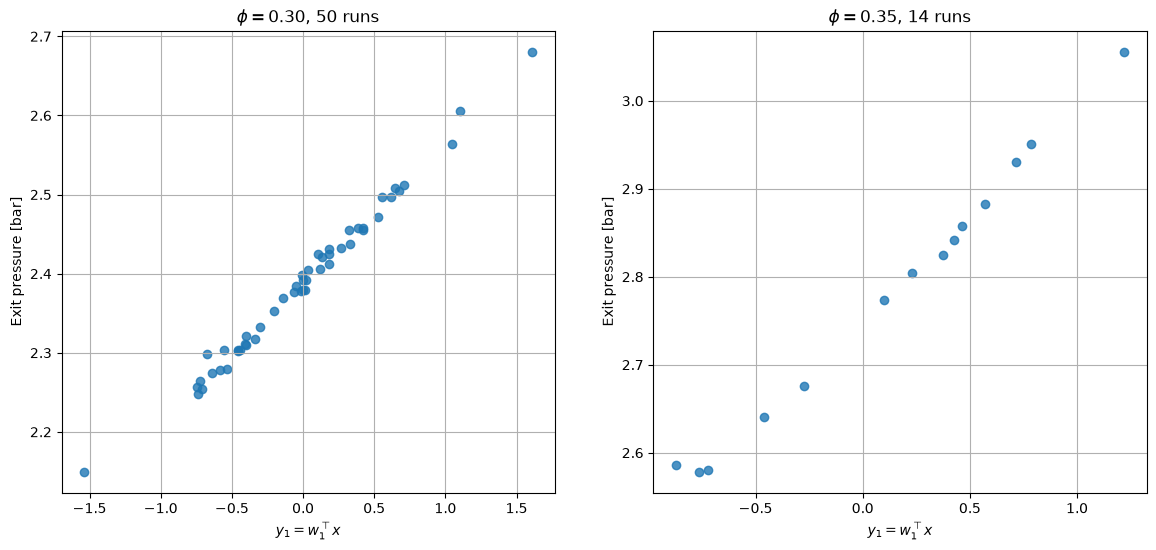

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, phi in zip(axes, phis):
    d = ~val[phi]
    ac.plotting.plot_sufficient_summary(sub[phi], X=X[phi][d], f=f[phi][d], ax=ax,
                                        qoi_label='Exit pressure [bar]')
    ax.set_title(rf'$\phi = {phi}$, {d.sum()} runs')
    ax.grid(True)

Both plots show a tight one-dimensional trend, which we use for the uncertainty quantification below.

The components of $\mathbf w$ measure how sensitive the exit pressure is to each input. We print them beside the published values: [[1]](https://doi.org/10.1016/j.jcp.2015.09.001), Table 3 (4.8 bar) for φ = 0.30, and [[2]](https://doi.org/10.1137/1.9781611973860), Table 5.2 for φ = 0.35. Both agree to the 4 printed digits.

In [5]:
published = {'0.30': np.array([0.6506, 0.5565, -0.0002, 0.3685, -0.3566, -0.0196, 0.0607]),   # JCP 2015 Table 3, 4.8 bar
             '0.35': np.array([0.6996, 0.4823, -0.0270, 0.1997, -0.4738, -0.0602, 0.0957])}   # book Table 5.2, phi = 0.35
print(f'{"":>11}{"w, 0.30":>10}{"JCP T3":>9}{"w, 0.35":>10}{"book T5.2":>11}')
for i in range(m):
    print(f'{labels[i]:>11}{w["0.30"][i]:10.4f}{published["0.30"][i]:9.4f}{w["0.35"][i]:10.4f}{published["0.35"][i]:11.4f}')
for phi in phis:
    print(f'phi = {phi}: max |w - published| = {np.abs(w[phi] - published[phi]).max():.1e}')
    assert np.abs(w[phi] - published[phi]).max() < 1e-4

              w, 0.30   JCP T3   w, 0.35  book T5.2
        AoA    0.6506   0.6506    0.6996     0.6996
   Turb int    0.5565   0.5565    0.4823     0.4823
   Turb len   -0.0002  -0.0002   -0.0270    -0.0270
  Stag pres    0.3685   0.3685    0.1997     0.1997
  Stag enth   -0.3566  -0.3566   -0.4738    -0.4738
 Cowl trans   -0.0196  -0.0196   -0.0602    -0.0602
 Ramp trans    0.0607   0.0607    0.0957     0.0957
phi = 0.30: max |w - published| = 4.8e-05
phi = 0.35: max |w - published| = 4.2e-05


Angle of attack, turbulence intensity and the stagnation conditions (pressure and enthalpy) dominate $\mathbf w$; the turbulence length scale and the two transition locations matter little. The components are similar for the two values of φ, except that weight moves from the stagnation pressure to the stagnation enthalpy as φ increases ([[1]](https://doi.org/10.1016/j.jcp.2015.09.001) §5.1 discusses the physics).

Now the bootstrap. The first figure shows $\mathbf w$ with the range (minimum to maximum) of its 10 000 bootstrap replicates for each φ; the second shows histograms of the replicates for φ = 0.30, with $\mathbf w$ as red lines (compare [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) Fig. 8 and [[2]](https://doi.org/10.1137/1.9781611973860) Figs. 5.3–5.4).

bootstrap range of each component (min, max)
                   phi = 0.30        phi = 0.35
        AoA    0.594    0.707   -0.411    0.915
   Turb int    0.505    0.615   -0.606    0.923
   Turb len   -0.067    0.058   -0.947    0.952
  Stag pres    0.295    0.458   -0.886    0.848
  Stag enth   -0.418   -0.278   -0.956    0.701
 Cowl trans   -0.087    0.046   -0.727    0.884
 Ramp trans   -0.014    0.130   -0.838    0.778
largest range: phi = 0.30: 0.16, phi = 0.35: 1.90


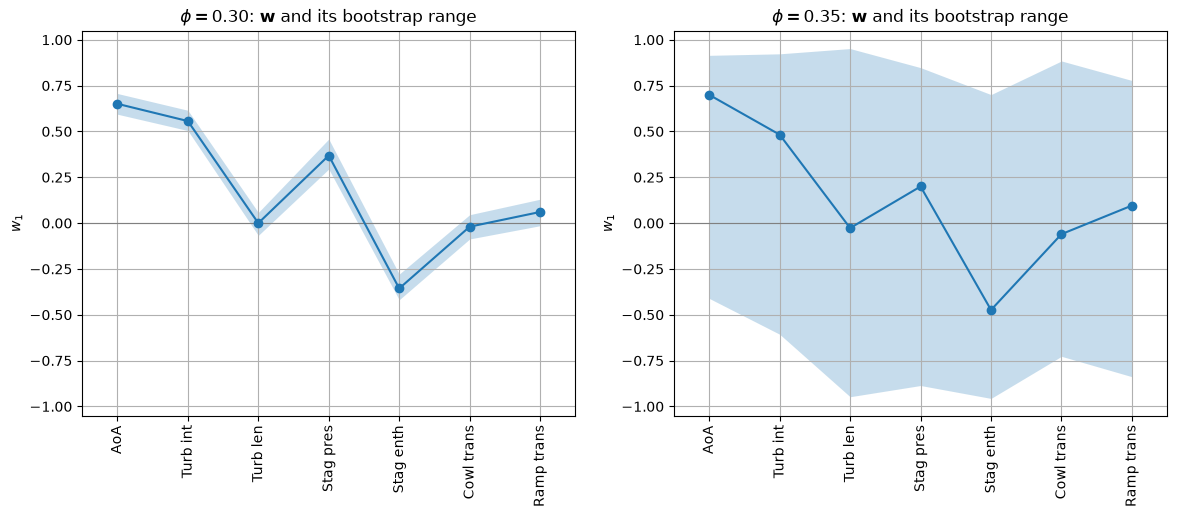

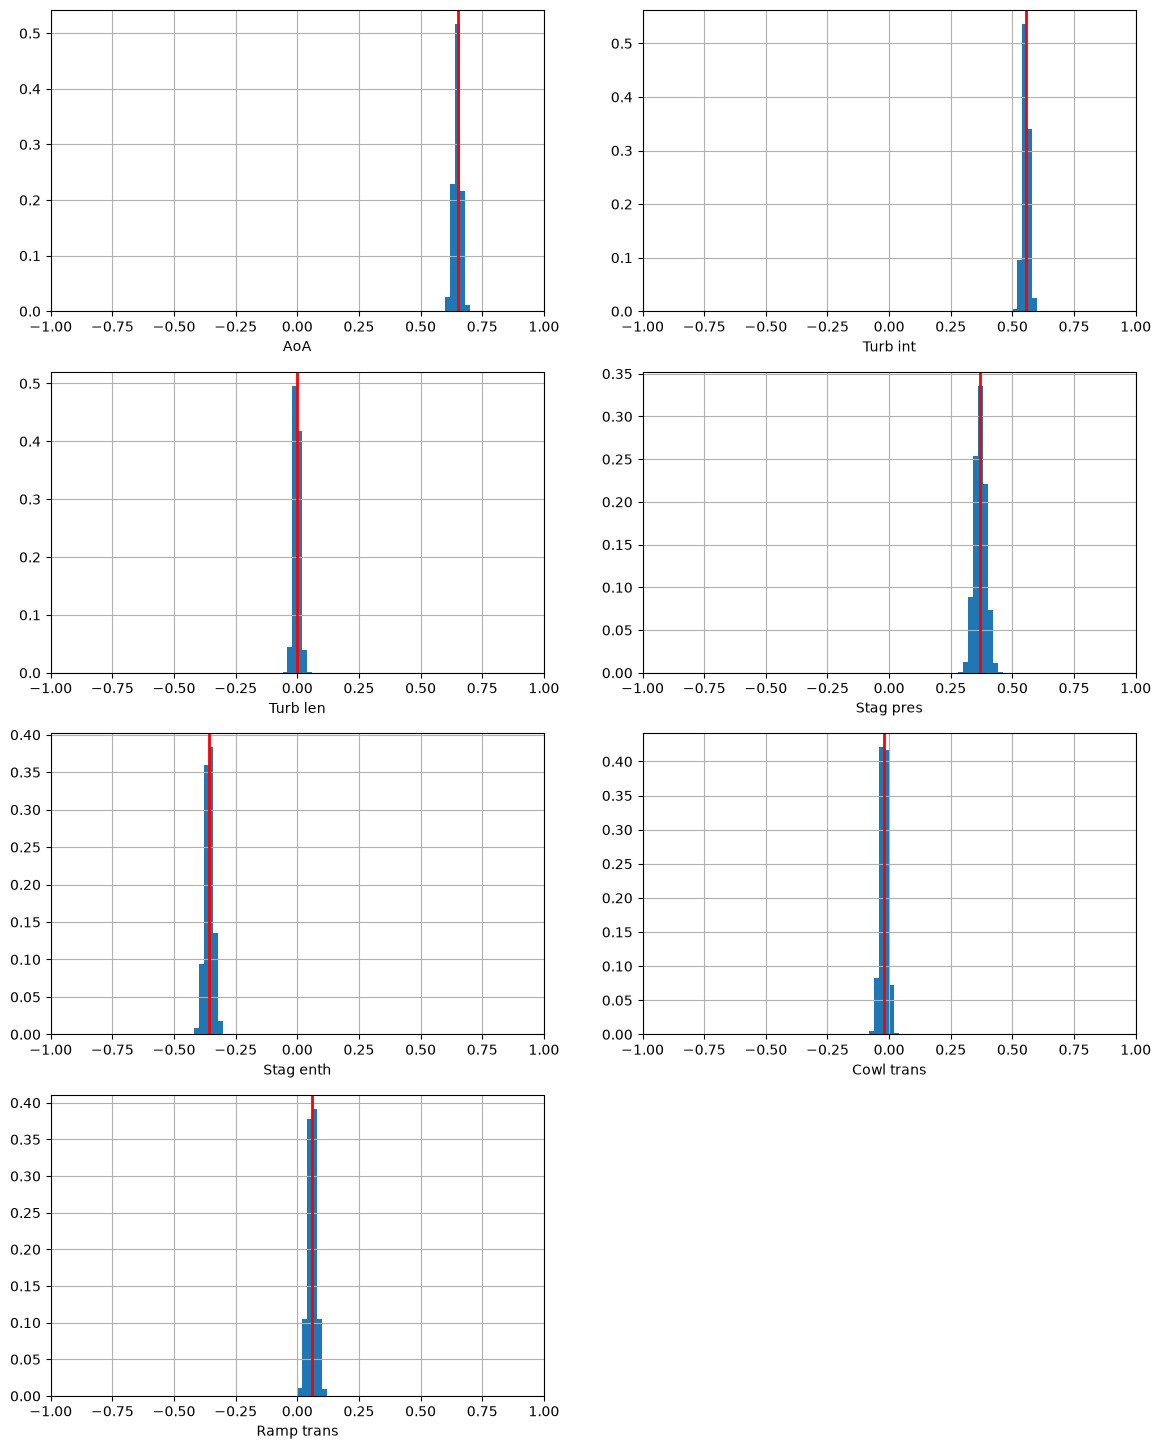

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, phi in zip(axes, phis):
    ac.plotting.plot_eigenvectors(sub[phi], indices=[0], interval='minmax', ax=[ax])
    ax.set_title(rf'$\phi = {phi}$: $\mathbf{{w}}$ and its bootstrap range')
    ax.grid(True)

boot = {phi: sub[phi].bootstrap_eigenvectors[:, :, 0] for phi in phis}   # (N, m), aligned with w
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for k, ax in enumerate(axes.flat[:m]):
    ax.hist(boot['0.30'][:, k], bins=100, range=(-1, 1), weights=np.full(len(boot['0.30']), 1 / len(boot['0.30'])))
    ax.axvline(w['0.30'][k], color='r', lw=2)
    ax.set_xlim(-1, 1)
    ax.set_xlabel(labels[k])
    ax.grid(True)
axes.flat[-1].set_visible(False)

print('bootstrap range of each component (min, max)')
print(f'{"":>11}{"phi = 0.30":>18}{"phi = 0.35":>18}')
for k in range(m):
    print(f'{labels[k]:>11}' + ''.join(f'{boot[phi][:, k].min():9.3f}{boot[phi][:, k].max():9.3f}' for phi in phis))
print('largest range: ' + ', '.join(f'phi = {phi}: {np.ptp(boot[phi], axis=0).max():.2f}' for phi in phis))

For φ = 0.30 the histograms are concentrated around $\mathbf w$, and the bootstrap ranges are narrow, which gives confidence in $\mathbf w$. For φ = 0.35 the ranges cover almost all of $[-1, 1]$: with 14 runs (twice the number of inputs), many resamples cannot determine the linear fit. The confidence for φ = 0.35 comes instead from the φ = 0.30 results, the similarity of the two vectors, and the clear trend in the summary plot ([[1]](https://doi.org/10.1016/j.jcp.2015.09.001) §5.2).

### Range of the exit pressure

The summary plots suggest that $f$ is a monotonic function of the active variable. Then $f$ is largest where $\mathbf w^T\mathbf x$ is largest over the cube, and smallest where it is smallest ([[1]](https://doi.org/10.1016/j.jcp.2015.09.001) eqs. (26)–(27)):

$$
\mathbf x_{max} = \underset{-1\le\mathbf x\le 1}{\operatorname{argmax}}\ \mathbf w^T\mathbf x = \operatorname{sign}(\mathbf w), \qquad \mathbf x_{min} = \underset{-1\le\mathbf x\le 1}{\operatorname{argmin}}\ \mathbf w^T\mathbf x = -\operatorname{sign}(\mathbf w).
$$

The two validation runs of each file are the simulations at these corners: four runs in all, two for each φ. In the plots below, the design runs are blue dots and the validation runs red squares (compare [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) Fig. 7 and [[2]](https://doi.org/10.1137/1.9781611973860) Fig. 5.2). The validation runs sit at the ends of the trend, so they estimate the range of the exit pressure.

The stored corners (the same two points in both files) differ from $\pm\operatorname{sign}(\mathbf w)$ in one component, the cowl transition location: $w_6 < 0$ for both φ, so $\mathbf x_{min}$ has the cowl transition at its upper bound, while the stored minimum corner has it at its lower bound. The corners were presumably chosen with an earlier estimate of $\mathbf w$. The effect is small, since $|w_6| \le 0.06$ and its bootstrap range includes 0; [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) §5.3 discusses this sign sensitivity of small components. We therefore use $\mathbf x_{min} = -\operatorname{sign}(\mathbf w)$, not the stored corner, in the safe-box problem below.

phi = 0.30: -sign(w) = [-1 -1  1 -1  1  1 -1], stored min corner = [-1 -1  1 -1  1 -1 -1], differ in: Cowl trans; w^T x at the stored corners = [-1.9734  1.9734], range of w^T x over the cube = +-2.0127
    exit pressure at the validation runs: [2.0861 2.7295] bar; design runs: 2.1495 to 2.6804 bar
phi = 0.35: -sign(w) = [-1 -1  1 -1  1  1 -1], stored min corner = [-1 -1  1 -1  1 -1 -1], differ in: Cowl trans; w^T x at the stored corners = [-1.918  1.918], range of w^T x over the cube = +-2.0384
    exit pressure at the validation runs: [2.2724 3.1274] bar; design runs: 2.5783 to 3.0557 bar


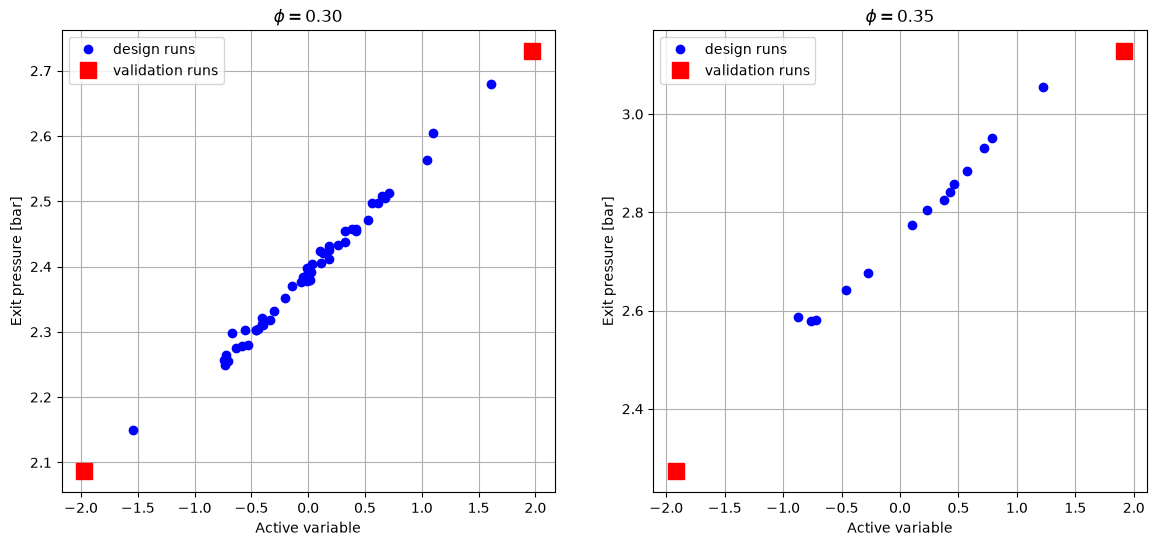

In [7]:
xmin = {phi: -np.sign(w[phi]) for phi in phis}
Z = {phi: space.to_normalized(X[phi]) for phi in phis}
y = {phi: Z[phi] @ w[phi] for phi in phis}
for phi in phis:
    corner = np.sign(Z[phi][val[phi]][0])   # the stored minimum corner (its entries are +-0.99999...)
    print(f'phi = {phi}: -sign(w) = {xmin[phi].astype(int)}, stored min corner = {corner.astype(int)}, '
          f'differ in: {", ".join(labels[i] for i in np.flatnonzero(corner != xmin[phi]))}; '
          f'w^T x at the stored corners = {np.round(y[phi][val[phi]], 4)}, '
          f'range of w^T x over the cube = +-{np.abs(w[phi]).sum():.4f}')
    print(f'    exit pressure at the validation runs: {f[phi][val[phi]]} bar; '
          f'design runs: {f[phi][~val[phi]].min():.4f} to {f[phi][~val[phi]].max():.4f} bar')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, phi in zip(axes, phis):
    d = ~val[phi]
    ax.plot(y[phi][d], f[phi][d], 'bo', label='design runs')
    ax.plot(y[phi][val[phi]], f[phi][val[phi]], 'rs', ms=12, label='validation runs')
    ax.grid(True)
    ax.legend(loc=2)
    ax.set_xlabel('Active variable')
    ax.set_ylabel('Exit pressure [bar]')
    ax.set_title(rf'$\phi = {phi}$')

### Constraining the exit pressure

Suppose the engine is safe while the exit pressure stays below 2.8 bar, and nears unsafe operation above it. Which inputs keep it safe? With the one-dimensional structure, we fit a response surface $g$ to the pairs $(y_i, f_i)$, $y_i = \mathbf w^T\mathbf x_i$, find the largest value $y_{max}$ of the active variable at which the surface stays safe, and map that back to the inputs.

As in [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) §5.4 and [[2]](https://doi.org/10.1137/1.9781611973860) §5.1.3, $g$ is a quadratic fitted by least squares to all the runs of each file: 52 for φ = 0.30 and 16 for φ = 0.35, the validation runs included. As a margin, we require the upper 99 % prediction limit, not $g$ itself, to stay below 2.8 bar. For a quadratic fit with design matrix $\mathbf B$ (rows $\mathbf b(y_i)^T$, $\mathbf b(y) = [1, y, y^2]^T$), residual standard deviation $s$ and $\nu = M - 3$ degrees of freedom, the limit is

$$
g(y) + q\, s\,\sqrt{1 + \mathbf b(y)^T(\mathbf B^T\mathbf B)^{-1}\mathbf b(y)}.
$$

`ac.predict_interval(poly, X, level=0.99, side="upper")` computes it with the Student's $t$ quantile $q = t_{\nu,0.99}$, which is exact when the errors are Gaussian. [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) and [[2]](https://doi.org/10.1137/1.9781611973860) use the normal quantile $q = z_{0.99} \approx 2.33$ (the "Prediction + 2.33 se" of [[2]](https://doi.org/10.1137/1.9781611973860) Fig. 5.5). To follow them, we multiply v1's half-width by $z_{0.99}/t_{\nu,0.99}$. The $t$ quantile is larger, so v1's own limit is slightly more conservative; we print both. The simulations are deterministic, so the "errors" are model discrepancy, not noise, and the 99 % has no probability meaning here ([[1]](https://doi.org/10.1016/j.jcp.2015.09.001), footnote 1); the limit is only a conservative margin. The 2016 notebook used the leverage of a straight-line fit, $1/M + (y - \bar y)^2/S_{yy}$, which only approximates the quadratic's; its numbers are reproduced at the end of the next section.

We find $y_{max}$ with a root finder on the range of the active variable over the cube, $[-\sum_i|w_i|, \sum_i|w_i|]$. When the limit stays below 2.8 bar on the whole range, the constraint is inactive and every input is safe. To evaluate the limit at a value $y$ we pass `ac.predict_interval` the point $\mathbf x = y\,\operatorname{sign}(\mathbf w)/\sum_i|w_i|$ of the cube, for which $\mathbf w^T\mathbf x = y$.

The in-sample $R^2$ is the one [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) and [[2]](https://doi.org/10.1137/1.9781611973860) report; we also print v1's leave-one-out $R^2$.

In [8]:
poly, ymax, ymax_t = {}, {}, {}
z99 = st.norm.ppf(0.99)

def limit(phi, yy, quantile='normal'):
    """Upper 99 % prediction limit of the quadratic at active-variable values yy."""
    yy = np.atleast_1d(yy)
    Xq = space.from_normalized(np.outer(yy / np.abs(w[phi]).sum(), np.sign(w[phi])))
    iv = ac.predict_interval(poly[phi], Xq, level=0.99, side='upper')
    scale = z99 / st.t.ppf(0.99, iv.dof) if quantile == 'normal' else 1.0
    return iv.estimate + (iv.upper - iv.estimate) * scale

def crossing(phi, quantile='normal'):
    """y_max where the limit reaches 2.8 bar, or None if it stays below on the whole range."""
    yb = np.abs(w[phi]).sum()
    if limit(phi, yb, quantile)[0] < 2.8:
        return None
    return op.brentq(lambda t: limit(phi, t, quantile)[0] - 2.8, -yb, yb, xtol=1e-12)

for phi in phis:
    poly[phi] = ac.fit_surrogate(X=X[phi], f=f[phi], subspace=sub[phi], kind='poly', degree=2)
    r = poly[phi].residuals
    R2 = 1 - r @ r / np.sum((f[phi] - f[phi].mean())**2)
    dof = len(f[phi]) - 3
    ymax[phi], ymax_t[phi] = crossing(phi), crossing(phi, 't')
    yb = np.abs(w[phi]).sum()
    print(f'phi = {phi}: M = {len(f[phi])}, R^2 = {R2:.4f} (leave-one-out {poly[phi].loo_r_squared:.4f}), '
          f'nu = {dof}, t = {st.t.ppf(0.99, dof):.3f} vs z = {z99:.3f}')
    print(f'    limit at the top of the range (y = {yb:.4f}): {limit(phi, yb)[0]:.4f} bar; '
          + ('constraint inactive: the whole cube is safe' if ymax[phi] is None else
             f'y_max = {ymax[phi]:.4f} (with t: {ymax_t[phi]:.4f})'))

phi = 0.30: M = 52, R^2 = 0.9926 (leave-one-out 0.9899), nu = 49, t = 2.405 vs z = 2.326
    limit at the top of the range (y = 2.0127): 2.7857 bar; constraint inactive: the whole cube is safe
phi = 0.35: M = 16, R^2 = 0.9927 (leave-one-out 0.9821), nu = 13, t = 2.650 vs z = 2.326
    limit at the top of the range (y = 2.0384): 3.2337 bar; y_max = -0.0284 (with t: -0.0574)


The $R^2$ values are those of [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) for φ = 0.30 (0.993); for φ = 0.35, [[2]](https://doi.org/10.1137/1.9781611973860) reports 0.998, a little higher than ours. For φ = 0.30 the prediction limit stays below 2.8 bar over the whole range of the active variable, so the safety constraint is inactive. The plots show the quadratic, the limit, the threshold, and the safe region of the active variable shaded (compare [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) Fig. 10 and [[2]](https://doi.org/10.1137/1.9781611973860) Fig. 5.5).

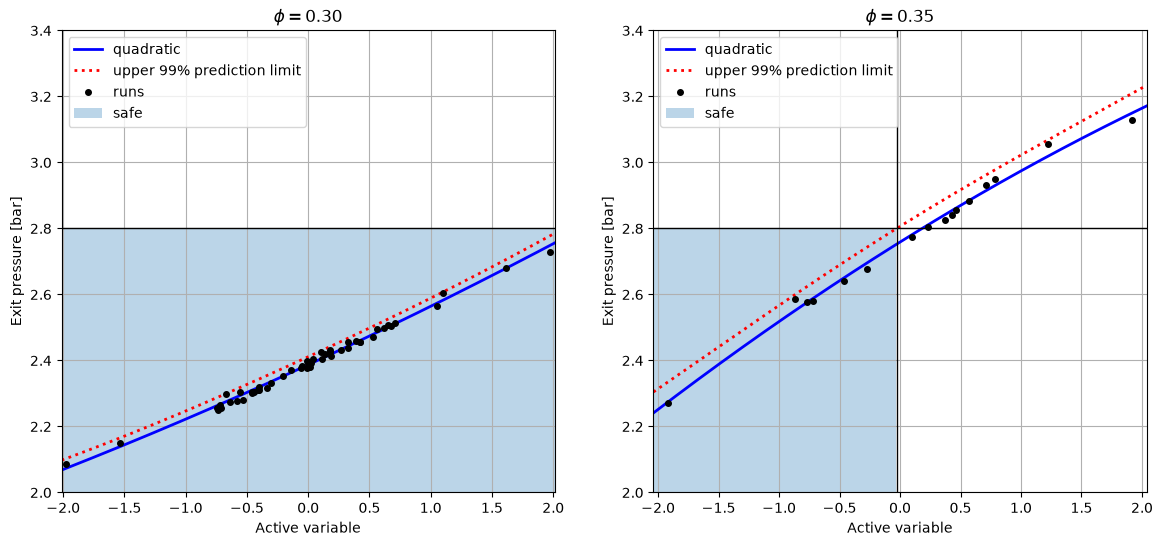

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, phi in zip(axes, phis):
    yb = np.abs(w[phi]).sum()
    t = np.linspace(-yb, yb, 400)
    top = yb if ymax[phi] is None else ymax[phi]
    ax.plot(t, poly[phi].evaluate(t[:, None]), 'b-', lw=2, label='quadratic')
    ax.plot(t, limit(phi, t), 'r:', lw=2, label='upper 99% prediction limit')
    ax.plot(y[phi], f[phi], 'ko', ms=4, label='runs')
    ax.axhline(2.8, color='k', lw=1)
    ax.fill_between(t[t <= top], 2, 2.8, alpha=.3, label='safe')
    if ymax[phi] is not None:
        ax.axvline(ymax[phi], color='k', lw=1)
    ax.set_xlim(-yb, yb)
    ax.set_ylim(2, 3.4)
    ax.grid(True)
    ax.legend(loc=2)
    ax.set_xlabel('Active variable')
    ax.set_ylabel('Exit pressure [bar]')
    ax.set_title(rf'$\phi = {phi}$')

The set of safe normalized inputs is $S = \{\mathbf x : \mathbf w^T\mathbf x \leq y_{max},\ -\mathbf 1 \leq \mathbf x\leq \mathbf 1\}$ ([[1]](https://doi.org/10.1016/j.jcp.2015.09.001) eq. (28)). Its bound couples the inputs: the safe range of the angle of attack, for example, depends on the other inputs. To get independent ranges, we find the largest box inside $S$ with one corner at $\mathbf x_{min} = -\operatorname{sign}(\mathbf w)$ ([[1]](https://doi.org/10.1016/j.jcp.2015.09.001) eq. (29)):

$$
\underset{\mathbf x\in S}{\text{maximize}}\ \prod_{i=1}^m|x_i-x_{i,min}|.
$$

We maximize the logarithm of the product with SLSQP. The box between $\mathbf x_{min}$ and the maximizer, mapped back to physical units, gives a range for each input in which every combination is safe according to the quadratic model. We print the inputs whose range is restricted.

In [10]:
def safe_box(phi, y_top):
    """Lower and upper physical bounds of the largest box in S with a corner at xmin."""
    if y_top is None:
        return lower.copy(), upper.copy()
    x0 = 0.5 * xmin[phi]   # feasible: w^T x0 = -sum|w|/2 < y_top
    res = op.minimize(lambda x: -np.sum(np.log(np.abs(x - xmin[phi]))), x0, method='SLSQP',
                      bounds=[(-1, 1)] * m, constraints={'type': 'ineq', 'fun': lambda x: y_top - x @ w[phi]})
    assert res.success, res.message
    corners = np.sort(space.from_normalized(np.vstack([xmin[phi], res.x])), axis=0)
    return corners[0], corners[1]

box, box_t = {}, {}
for phi in phis:
    box[phi], box_t[phi] = safe_box(phi, ymax[phi]), safe_box(phi, ymax_t[phi])
    lo, hi = box[phi]
    changed = np.flatnonzero(~np.isclose(lo, lower, rtol=1e-9) | ~np.isclose(hi, upper, rtol=1e-9))
    print(f'phi = {phi}: ' + ('every input keeps its full range' if changed.size == 0 else 'safe ranges'))
    for i in changed:
        print(f'{labels[i]:>14}: {lo[i]:.4g} to {hi[i]:.4g} {units[i]}'
              f'   (with t: {box_t[phi][0][i]:.4g} to {box_t[phi][1][i]:.4g})')

phi = 0.30: every input keeps its full range
phi = 0.35: safe ranges
           AoA: 2.6 to 3.193 deg   (with t: 2.6 to 3.179)
      Turb int: 0.1 to 0.8742 %   (with t: 0.1 to 0.856)
     Stag enth: 3.265e+06 to 3.428e+06 J/kg   (with t: 3.269e+06 to 3.428e+06)


For φ = 0.30 the 50 + 2 runs keep every input safe. [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) Table 4 restricts the angle of attack to at most 4.29° and the turbulence intensity to at most 1.88 % at 4.8 bar; we do not reproduce that from these data, where the limit stays below 2.8 bar (it reaches 2.7857 bar at the top of the range).

For φ = 0.35 the angle of attack must stay below 3.193°, the turbulence intensity below 0.874 %, and the stagnation enthalpy above 3.265 MJ/kg. [[2]](https://doi.org/10.1137/1.9781611973860) §5.1.3 reports the same three restrictions with somewhat looser values: angle of attack below 3.31°, turbulence intensity below 1.1 %, and stagnation enthalpy above 3.23 MJ/kg (the book prints "2.23 MJ/kg", a typo, since the input range starts at 3.0551 MJ/kg). Its $R^2$ is also higher (0.998 against 0.9927 here), so the book's fit was probably not computed exactly as here; we do not know the remaining difference. With v1's $t$ quantile the restrictions are a little tighter (printed in parentheses above).

**Check: the 2016 procedure.** The 2016 notebook found $y_{max}$ as the nearest point of a grid on $[-2, 3]$ with the straight-line leverage, used the stored corner run as $\mathbf x_{min}$, and ran in Python 2, where `1/M` is 0. The cell below repeats that procedure and prints the same 3-digit table for φ = 0.35 as the 2016 notebook (angle of attack 3.25, turbulence intensity 0.953, stagnation enthalpy 3.25e6), and then the values with Python 3 division. For φ = 0.30 the 2016 procedure also gives the full box, up to the stored corners, which lie a few millionths inside the cube.

In [11]:
def box_2016(phi, one_over_M):
    """The 2016 notebook's safe box: straight-line leverage, grid search, stored corner as xmin."""
    yy, ff = y[phi], f[phi]
    c = np.polyfit(yy, ff, 2)
    s = np.sqrt(np.sum((ff - np.polyval(c, yy))**2) / (len(ff) - 3))
    lim = lambda t: np.polyval(c, t) + 2.33 * s * np.sqrt(1 + one_over_M + (t - yy.mean())**2 / np.sum((yy - yy.mean())**2))
    grid = np.linspace(-2, 3, 800)
    y_top = grid[np.argmin(np.abs(lim(grid) - 2.8))]
    zmin, zmax = Z[phi][val[phi]]
    res = op.minimize(lambda x: -np.sum(np.log(np.abs(x - zmin))), zmax, bounds=[(-1, 1)] * m,
                      constraints={'type': 'ineq', 'fun': lambda x: y_top - x @ w[phi]})
    return np.sort(space.from_normalized(np.vstack([zmin, res.x])), axis=0)

for name, one_over_M in [('Python 2 (1/M = 0)', 0.0), ('Python 3 (1/M = 1/16)', 1 / 16)]:
    lo, hi = np.round(box_2016('0.35', one_over_M), 4)
    print(f'phi = 0.35, 2016 procedure, {name}:')
    for i in (0, 1, 4):
        print(f'    {lo[i]:0.2e} \t {hi[i]:0.2e}\t {labels[i]}    ({lo[i]:.4g} to {hi[i]:.4g})')
lo, hi = box_2016('0.30', 0.0)
shrink = np.max(np.maximum(lo - lower, upper - hi) / (upper - lower))
gap = np.max(1 - np.abs(Z['0.30'][val['0.30']]))
print(f'phi = 0.30, 2016 procedure: largest change of a range, relative to its width: {shrink:.1e} '
      f'(the stored corners lie within {gap:.1e} of +-1 in normalized coordinates)')

phi = 0.35, 2016 procedure, Python 2 (1/M = 0):
    2.60e+00 	 3.25e+00	 AoA    (2.6 to 3.253)
    1.00e-01 	 9.53e-01	 Turb int    (0.1 to 0.9528)
    3.25e+06 	 3.43e+06	 Stag enth    (3.248e+06 to 3.428e+06)
phi = 0.35, 2016 procedure, Python 3 (1/M = 1/16):
    2.60e+00 	 3.25e+00	 AoA    (2.6 to 3.25)
    1.00e-01 	 9.49e-01	 Turb int    (0.1 to 0.9489)
    3.25e+06 	 3.43e+06	 Stag enth    (3.249e+06 to 3.428e+06)
phi = 0.30, 2016 procedure: largest change of a range, relative to its width: 1.7e-06 (the stored corners lie within 3.4e-06 of +-1 in normalized coordinates)


The three differences from the 2016 values are the exact quadratic leverage, Python 3 division, and $\mathbf x_{min} = -\operatorname{sign}(\mathbf w)$ instead of the stored corner. The last one matters most: it moves the box's fixed corner in the cowl-transition coordinate, which tightens the angle of attack from 3.250° to 3.193°.

### The book's φ = 0.30 runs

The φ = 0.35 file also holds the exit pressure at φ = 0.30 for the same 14 design runs, the φ = 0.30 study of [[2]](https://doi.org/10.1137/1.9781611973860) §5.1. Its two validation runs are not available (the file stores `nan`), so the quadratic below uses 14 runs, where the book used 16. These runs are not those of [[1]](https://doi.org/10.1016/j.jcp.2015.09.001): they sit 0.06 to 0.10 bar above a linear fit to the 50 runs (printed below), so the two φ = 0.30 studies differ systematically, for reasons we do not know.

In [12]:
d = ~val['0.35']
fb = f_book30[d]
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)   # the OLS-on-uniform warning, as above
    sub_b = ac.active_subspace(X=X['0.35'][d], f=fb, space=space, estimator='ols', n=1)
w_b = sub_b.W1[:, 0]
book_030 = np.array([0.6933, 0.5033, 0.0067, 0.3468, -0.3732, -0.0524, 0.0605])   # book Table 5.2, phi = 0.30
print(f'w: {np.round(w_b, 4)}\nbook Table 5.2, phi = 0.30: {book_030}; max |difference| = {np.abs(w_b - book_030).max():.1e}')
assert np.abs(w_b - book_030).max() < 1e-4

# offset from the JCP phi = 0.30 runs: residuals of the book runs about a linear fit to the 50 JCP design runs
A50 = np.column_stack([np.ones((~val['0.30']).sum()), Z['0.30'][~val['0.30']]])
u50 = np.linalg.lstsq(A50, f['0.30'][~val['0.30']], rcond=None)[0]
offset = fb - np.column_stack([np.ones(d.sum()), Z['0.35'][d]]) @ u50
print(f'book phi = 0.30 runs minus the linear fit to the JCP runs: mean {offset.mean():.3f} bar, '
      f'range {offset.min():.3f} to {offset.max():.3f} bar')

poly_b = ac.fit_surrogate(X=X['0.35'][d], f=fb, subspace=sub_b, kind='poly', degree=2)
r = poly_b.residuals
print(f'quadratic on 14 runs: R^2 = {1 - r @ r / np.sum((fb - fb.mean())**2):.4f} (book, 16 runs: 0.997)')
w['book'], poly['book'], xmin['book'] = w_b, poly_b, -np.sign(w_b)
ymax['book'] = crossing('book')
lo, hi = safe_box('book', ymax['book'])
print(f'y_max = {ymax["book"]:.4f}; safe ranges: AoA {lo[0]:.4g} to {hi[0]:.4g} deg, '
      f'Turb int {lo[1]:.4g} to {hi[1]:.4g} % (book: AoA below 3.99 deg, Turb int below 1.8 %)')
for i in range(m):
    if i not in (0, 1):
        assert np.isclose(lo[i], lower[i], rtol=1e-9) and np.isclose(hi[i], upper[i], rtol=1e-9)

w: [ 0.6933  0.5033  0.0067  0.3468 -0.3732 -0.0524  0.0605]
book Table 5.2, phi = 0.30: [ 0.6933  0.5033  0.0067  0.3468 -0.3732 -0.0524  0.0605]; max |difference| = 4.4e-05
book phi = 0.30 runs minus the linear fit to the JCP runs: mean 0.076 bar, range 0.057 to 0.097 bar
quadratic on 14 runs: R^2 = 0.9923 (book, 16 runs: 0.997)


y_max = 1.4924; safe ranges: AoA 2.6 to 3.934 deg, Turb int 0.1 to 1.753 % (book: AoA below 3.99 deg, Turb int below 1.8 %)


The direction reproduces [[2]](https://doi.org/10.1137/1.9781611973860) Table 5.2, and the safe box restricts the same two inputs as the book, with close values (angle of attack below 3.934° here against 3.99° in the book, turbulence intensity below 1.753 % against 1.8 %), even without the two validation runs.

### Cumulative distribution function

Finally, we estimate the cumulative distribution function of the exit pressure. We sample the inputs uniformly, compute the active variable, and evaluate the quadratic surface there. We use 100 000 samples and the empirical distribution function; [[1]](https://doi.org/10.1016/j.jcp.2015.09.001) used 5000 samples and a Gaussian kernel density estimate (its Fig. 11). The dashed lines are the exit pressures of the validation runs, the estimated range of $f$.

phi = 0.30: median 2.387 bar, 5-95 % range 2.230 to 2.555 bar, fraction of the surface above 2.8 bar 0.000
phi = 0.35: median 2.759 bar, 5-95 % range 2.530 to 2.964 bar, fraction of the surface above 2.8 bar 0.384


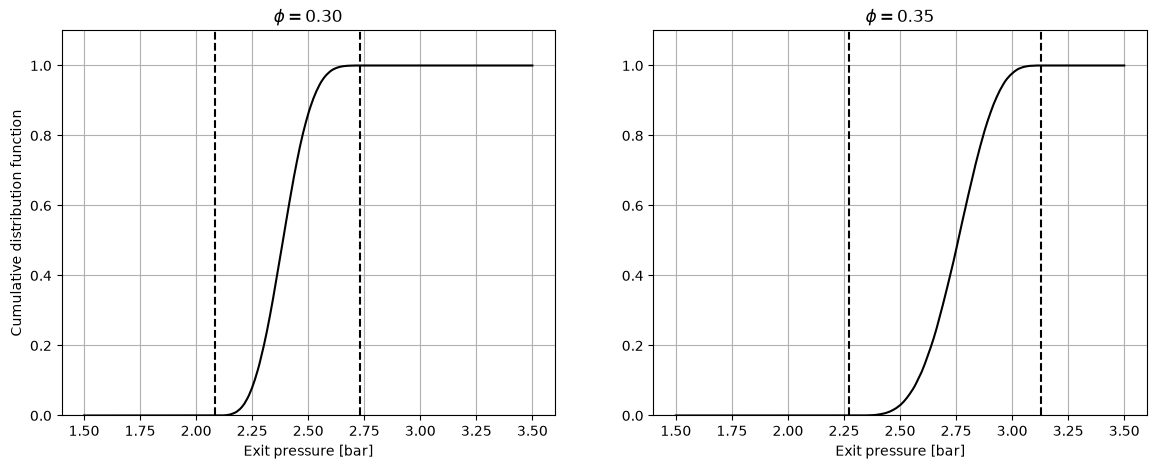

In [13]:
N = 100_000
Zs = rng.uniform(-1, 1, (N, m))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
grid = np.linspace(1.5, 3.5, 300)
for ax, phi in zip(axes, phis):
    gs = np.sort(poly[phi].evaluate((Zs @ w[phi])[:, None]))
    ax.plot(grid, np.searchsorted(gs, grid, side='right') / N, 'k-')
    ax.vlines(f[phi][val[phi]], 0, 1.1, 'k', 'dashed')
    ax.set_ylim(0, 1.1)
    ax.grid(True)
    ax.set_xlabel('Exit pressure [bar]')
    ax.set_title(rf'$\phi = {phi}$')
    q05, q50, q95 = np.quantile(gs, [.05, .5, .95])
    print(f'phi = {phi}: median {q50:.3f} bar, 5-95 % range {q05:.3f} to {q95:.3f} bar, '
          f'fraction of the surface above 2.8 bar {np.mean(gs > 2.8):.3f}')
axes[0].set_ylabel('Cumulative distribution function');

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 28 s
